# Text scam classifier

This notebook combines the two verified SMS datasets, uses word and character TF-IDF features, selects a classical classifier on validation data, and evaluates once on a held-out test set. Label `1` always means scam.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = Path.cwd().resolve()
while not (MODEL_DIR / "src").is_dir():
    if MODEL_DIR.parent == MODEL_DIR:
        raise RuntimeError("Run this notebook from inside the model directory tree.")
    MODEL_DIR = MODEL_DIR.parent
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_preparation import prepare_sms_dataset
from src.train_models import train_text_model

sns.set_theme(style='whitegrid')

## Prepare and inspect the standardized data

Exact duplicate messages and empty messages are removed before splitting. We preserve a `source` column so UCI and Mendeley provenance remains visible.

{'before_cleaning': {'records': 11543, 'class_distribution': {'0': 9669, '1': 1874}, 'by_source': {'Mendeley': 5971, 'UCI': 5572}}, 'after_cleaning': {'records': 6056, 'class_distribution': {'0': 4994, '1': 1062}, 'by_source': {'UCI': 5158, 'Mendeley': 898}}, 'removed_empty': 0, 'removed_exact_duplicates_or_empty': 5487}
Shape: (6056, 3)


,text,label,source
0,"Go until jurong point, crazy.. Available only ...",0,UCI
1,Ok lar... Joking wif u oni...,0,UCI
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,UCI
3,U dun say so early hor... U c already then say...,0,UCI
4,"Nah I don't think he goes to usf, he lives aro...",0,UCI


Missing values:
 text      0
label     0
source    0
dtype: int64
Duplicate messages: 0
Class distribution:
 label
legitimate    4994
scam          1062
Name: count, dtype: int64


C:\Users\Sabyasachi Samanta\AppData\Local\Temp\ipykernel_41720\4197300021.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['legitimate', 'scam'])


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
5,1,FreeMsg Hey there darling it's been 3 week's n...
8,1,WINNER!! As a valued network customer you have...


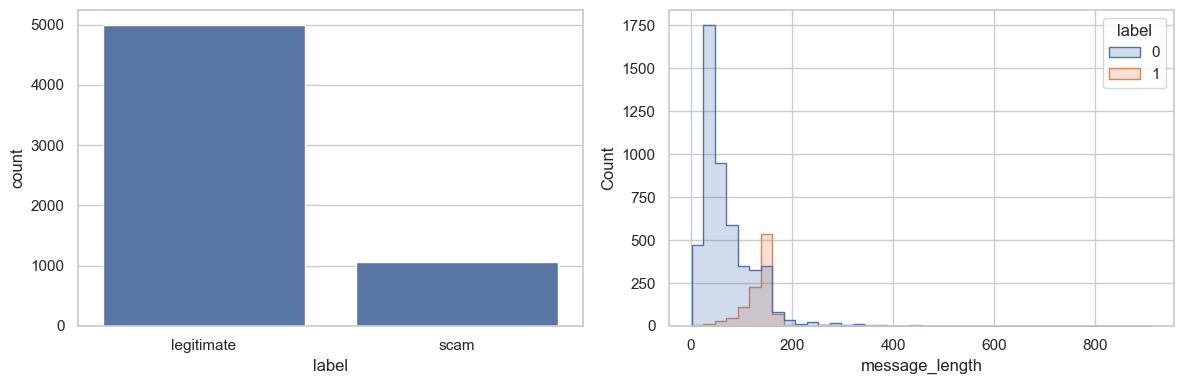

In [2]:
sms, cleaning_report = prepare_sms_dataset(save=True)
print(cleaning_report)
print('Shape:', sms.shape)
display(sms.head())
print('Missing values:\n', sms.isna().sum())
print('Duplicate messages:', sms.duplicated('text').sum())
print('Class distribution:\n', sms.label.value_counts().rename(index={0: 'legitimate', 1: 'scam'}))

sms['message_length'] = sms.text.str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=sms, x='label', ax=axes[0])
axes[0].set_xticklabels(['legitimate', 'scam'])
sns.histplot(data=sms, x='message_length', hue='label', bins=40, element='step', ax=axes[1])
plt.tight_layout()
display(sms.groupby('label').head(3)[['label', 'text']])

## Features, validation, and test evaluation

Each candidate pipeline learns two TF-IDF representations: word 1–2 grams capture phrases such as “verify account”, while character 3–5 grams help with URL fragments, spelling variants, and obfuscation. Complement Naive Bayes is a fast sparse-text baseline; balanced Logistic Regression models linear evidence; calibrated Linear SVM adds a margin-based comparison with valid probabilities. The test set is never used to select the model.

Selected on validation F1: LogisticRegression
Split sizes: {'train': 3633, 'validation': 1211, 'test': 1212}
Duplicate overlap checks: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}


,accuracy,precision_scam_or_phishing,recall_scam_or_phishing,f1_scam_or_phishing,pr_auc
ComplementNB,0.977704,0.969543,0.900943,0.933985,0.984026
LogisticRegression,0.988439,1.0,0.933962,0.965854,0.992367
CalibratedLinearSVC,0.985962,0.97561,0.943396,0.959233,0.993721


Held-out test metrics:


accuracy                      0.990924
precision_scam_or_phishing    0.976415
recall_scam_or_phishing       0.971831
f1_scam_or_phishing           0.974118
pr_auc                        0.993561
dtype: object

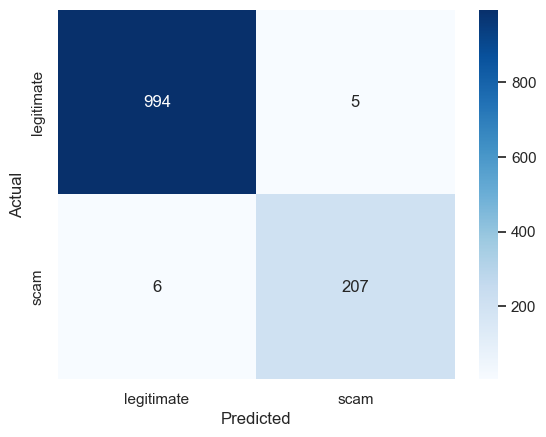

              precision    recall  f1-score      support
legitimate     0.994000  0.994995  0.994497   999.000000
malicious      0.976415  0.971831  0.974118   213.000000
accuracy       0.990924  0.990924  0.990924     0.990924
macro avg      0.985208  0.983413  0.984307  1212.000000
weighted avg   0.990910  0.990924  0.990916  1212.000000


In [3]:
result = train_text_model()
print('Selected on validation F1:', result['selected_model'])
print('Split sizes:', result['split_sizes'])
print('Duplicate overlap checks:', result['duplicate_messages_across_train_validation_test'])
validation = pd.DataFrame(result['validation_metrics']).T
display(validation[['accuracy', 'precision_scam_or_phishing', 'recall_scam_or_phishing', 'f1_scam_or_phishing', 'pr_auc']])
print('Held-out test metrics:')
display(pd.Series(result['test_metrics']).drop(['classification_report', 'confusion_matrix']))
sns.heatmap(result['test_metrics']['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=['legitimate', 'scam'], yticklabels=['legitimate', 'scam'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()
print(pd.DataFrame(result['test_metrics']['classification_report']).T)

## Error analysis

False positives involving genuine bank, OTP, account, or transaction language are especially important because these ordinary alerts can resemble scams. False negatives are scams that the model has labelled legitimate; review them to identify gaps in the training data.

In [4]:
display(result['error_analysis']['bank_or_otp_false_positives'])
display(result['error_analysis']['all_false_negatives'])

,text,actual,prediction,probability


,text,actual,prediction,probability
507,"Goal! Arsenal 4 (Henry, 7 v Liverpool 2 Henry ...",1,0,0.490682
559,2/2 146tf150p,1,0,0.248361
566,Rate Revsng soon.Xperience Beachside Living.Su...,1,0,0.427781
863,"Do you ever notice that when you're driving, a...",1,0,0.012679
958,"Latest News! Police station toilet stolen, cop...",1,0,0.251060
982,For sale - arsenal dartboard. Good condition b...,1,0,0.191598


## Saved pipeline and inference

The saved Joblib object includes the fitted TF-IDF vectorizers and selected classifier. Its `predict_proba(...)[..., 1]` is the scam probability, not an uncalibrated score.

In [5]:
from src.text_predictor import predict_text
artifact = MODEL_DIR / 'saved_model' / 'text_scam_pipeline.joblib'
print('Saved:', artifact, artifact.exists())
predict_text('URGENT: Your bank account is blocked. Verify your KYC immediately at http://example.test')

Saved: C:\Coding\Projects\ScaMail AI\model\saved_model\text_scam_pipeline.joblib True


{'prob': 0.925555, 'prediction': 'scam', 'model': 'text_classifier'}